In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.simulation import simulate_gbm
from src.black_scholes import bs_price, bs_delta
from src.hedging import compute_pnl, bs_delta_strategy

In [2]:
S0, K, sigma, T, n_steps = 100, 100, 0.2, 30/365, 30
dt = T / n_steps

S = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=42)
S_t = torch.tensor(S, dtype=torch.float32)

p0 = bs_price(S0, K, T, sigma)

In [3]:
tau = T - np.arange(n_steps) * dt

x1 = torch.log(S_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2 = torch.tensor(tau / T, dtype=torch.float32).expand(S_t.shape[0], n_steps)
features = torch.stack([x1, x2], dim=-1)

print(features.shape, features[0, 0])

torch.Size([100000, 30, 2]) tensor([0., 1.])


In [4]:
net_tc = nn.Sequential(
    nn.Linear(3, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)

In [ ]:
idx = torch.randint(0, S_t.shape[0], (10_000,))
S_b  = S_t[idx]
x1_b = x1[idx]
x2_b = x2[idx]



B = x1_b.shape[0]                    
delta_prev = torch.zeros(B)          
k = 0
inp = torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)   
delta_k = net_tc(inp).squeeze(-1)  

In [ ]:
delta_prev = torch.zeros(B)
deltas_list = []

for k in range(n_steps):
    inp =torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)       
    delta_k =  net_tc(inp).squeeze(-1)
    deltas_list.append(delta_k)
    delta_prev = delta_k
deltas = torch.stack(deltas_list, dim=1)
print(deltas.shape)

torch.Size([10000, 30])


In [10]:



def rollout(net, x1_b, x2_b):
    B = x1_b.shape[0]
    delta_prev = torch.zeros(B)
    deltas_list = []
    for k in range(n_steps):
        inp =torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)        # тройка признаков дня k (строка у тебя уже есть
        delta_k =  net(inp).squeeze(-1)
        deltas_list.append(delta_k)
        delta_prev = delta_k
    deltas = torch.stack(deltas_list, dim=1)
    return deltas

deltas.shape

torch.Size([10000, 30])

In [11]:
def pnl_torch(S_b, deltas, p0, K, c):
    payoff = torch.clamp(S_b[:, -1] - K, min=0)
    hedge_gain = (deltas * (S_b[:, 1:] - S_b[:, :-1])).sum(dim=1)

    zeros = torch.zeros(deltas.shape[0], 1)
    prev = torch.cat([zeros, deltas[:, :-1]], dim=1)
    costs = (c * S_b[:, :-1] * torch.abs(deltas - prev)).sum(dim=1)

    return p0 - payoff + hedge_gain - costs

In [12]:
with torch.no_grad():
    d = rollout(net_tc, x1_b, x2_b)
    p_t = pnl_torch(S_b, d, p0, K, c=0.01)

p_np = compute_pnl(S_b.numpy(), d.numpy(), p0, K, c=0.01)
print(p_t[:5])
print(p_np[:5])

tensor([ 1.9090,  1.7867, -3.6806,  1.7873, -2.3739])
[ 1.90904926  1.78672238 -3.68064042  1.78725912 -2.37385002]


In [16]:
net_tc = nn.Sequential(
    nn.Linear(3, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
w = torch.tensor(0.0, requires_grad=True)
alpha = 0.95
c = 0.01

optimizer = torch.optim.Adam([
    {"params": list(net_tc.parameters()), "lr": 1e-3},
    {"params": [w], "lr": 0.01},
])

In [17]:
for i in range(3000):
    idx = torch.randint(0, S_t.shape[0], (10_000,))
    S_b, x1_b, x2_b = S_t[idx], x1[idx], x2[idx]

    deltas = rollout(net_tc, x1_b, x2_b)
    pnl = pnl_torch(S_b, deltas, p0, K, c)

    loss = w + torch.clamp(-pnl - w, min=0).mean() / (1 - alpha)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i % 300 == 0:
        print(i, loss.item(), w.item())

0 33.13905715942383 0.009999999776482582
300 2.5087952613830566 2.096583604812622
600 2.443112373352051 2.2138214111328125
900 2.4318456649780273 2.2110354900360107
1200 2.4485232830047607 2.2085070610046387
1500 2.4293365478515625 2.2017152309417725
1800 2.424710512161255 2.1969377994537354
2100 2.422762632369995 2.1860077381134033
2400 2.4297618865966797 2.1843883991241455
2700 2.430006980895996 2.182594060897827


In [18]:
torch.save(net_tc.state_dict(), "../models/net_tc_c001.pt")

In [20]:
def cvar(pnl, alpha=0.95):
    losses = -pnl
    var = np.quantile(losses, alpha)
    return losses[losses >=var].mean()  

In [21]:
def report(name, pnl, deltas):
    prev = np.concatenate([np.zeros((deltas.shape[0], 1)), deltas[:, :-1]], axis=1)
    turnover = np.abs(deltas - prev).sum(axis=1).mean()
    print(f"{name:12s} mean={pnl.mean():.3f}  std={pnl.std():.3f}  CVaR95={cvar(pnl):.3f}  turnover={turnover:.2f}")

In [22]:
S_test = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=1)
S_test_t = torch.tensor(S_test, dtype=torch.float32)
x1_test = torch.log(S_test_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2_test = torch.tensor(tau / T, dtype=torch.float32).expand(S_test_t.shape[0], n_steps)

In [23]:
with torch.no_grad():
    d_net = rollout(net_tc, x1_test, x2_test).numpy()
d_bs   = bs_delta_strategy(S_test, K, T, sigma)
d_none = np.zeros_like(d_bs)

for name, d in [("No hedge", d_none), ("BS delta", d_bs), ("Network", d_net)]:
    pnl = compute_pnl(S_test, d, p0, K, c=c)
    report(name, pnl, d)

No hedge     mean=-0.016  std=3.466  CVaR95=10.064  turnover=0.00
BS delta     mean=-2.220  std=0.754  CVaR95=4.057  turnover=2.22
Network      mean=-1.243  std=0.636  CVaR95=2.408  turnover=1.24


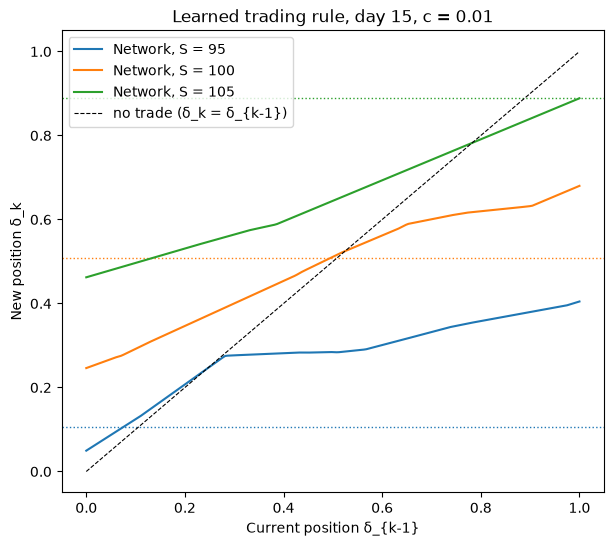

In [ ]:
import matplotlib.pyplot as plt

k = 15                                  
delta_prev_grid = torch.linspace(0, 1, 200)

fig, ax = plt.subplots(figsize=(7, 6))
for S_val, color in zip([95, 100, 105], ["C0", "C1", "C2"]):
    x1v = torch.full_like(delta_prev_grid, np.log(S_val / K) / (sigma * np.sqrt(T)))
    x2v = torch.full_like(delta_prev_grid, tau[k] / T)
    with torch.no_grad():
        out = net_tc(torch.stack([x1v, x2v, delta_prev_grid], dim=-1)).squeeze(-1)
    ax.plot(delta_prev_grid, out, color=color, label=f"Network, S = {S_val}")
    ax.axhline(bs_delta(S_val, K, tau[k], sigma), color=color, ls=":", lw=1)

ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="no trade (δ_k = δ_{k-1})")
ax.set_xlabel("Current position δ_{k-1}")
ax.set_ylabel("New position δ_k")
ax.set_title(f"Learned trading rule, day {k}, c = {c}")
ax.legend()
plt.savefig("../figures/no_trade_band.png", dpi=150, bbox_inches="tight")
plt.show()